# House Number Recognition Using CNN and the SVHN Dataset



**Students**
- Abdelrahman Ahmed Alazzazi
- Haitham Hani Dalloul

## Project objective
The objective is to train a simple Convolutional Neural Network (CNN) that classifies cropped house-number images into ten classes representing the digits 0 to 9.

## Work plan
1. Import the required libraries.
2. Load and inspect the SVHN dataset.
3. Display samples and examine class distribution.
4. Split and prepare the data.
5. Build and train a simple CNN.
6. Evaluate the model using accuracy, loss, a classification report, and a confusion matrix.
7. Inspect correct and incorrect predictions.
8. Save the trained model and the main results.

# 1. Import libraries

In [ ]:
# Run only if `tfds.load` is not available (see troubleshooting note at the end)
# %pip uninstall -y tf-datasets tensorflow-datasets tfds-nightly
# %pip install --no-cache-dir --force-reinstall tensorflow-datasets==4.9.10

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)
print("TFDS version:", getattr(tfds, '__version__', 'unknown'))
print("TFDS load available:", hasattr(tfds, "load"))

TensorFlow version: 2.20.0
TFDS version: 4.9.10
TFDS load available: True


# 2. Create folders for the saved results

In [ ]:
PROJECT_DIR = Path("/content/SVHN_Student_Project")
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "model"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /content/SVHN_Student_Project


# 3. Set the random seed

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


# 4. Load and split the SVHN dataset
The original training set is divided into 80% for training and 20% for validation. The original test set is kept for final evaluation.

In [ ]:
(train_raw, validation_raw, test_raw), info = tfds.load(
    "svhn_cropped",
    split=["train[:80%]", "train[80%:]", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

print("Dataset loaded successfully.")

Dataset svhn_cropped downloaded and prepared to /root/tensorflow_datasets/svhn_cropped/3.1.0. Subsequent calls will reuse this data.
Dataset loaded successfully.


# 5. Display dataset information

In [ ]:
print("Image shape:", info.features["image"].shape)
print("Image data type:", info.features["image"].np_dtype)
print("Number of classes:", info.features["label"].num_classes)
print("Original training images:", info.splits["train"].num_examples)
print("Original test images:", info.splits["test"].num_examples)

train_count = tf.data.experimental.cardinality(train_raw).numpy()
validation_count = tf.data.experimental.cardinality(validation_raw).numpy()
test_count = tf.data.experimental.cardinality(test_raw).numpy()

print("\nProject split:")
print("Training images:", train_count)
print("Validation images:", validation_count)
print("Testing images:", test_count)

Image shape: (32, 32, 3)
Image data type: <class 'numpy.uint8'>
Number of classes: 10
Original training images: 73257
Original test images: 26032

Project split:
Training images: 58606
Validation images: 14651
Testing images: 26032


# 6. Inspect one image

Image shape: (32, 32, 3)
Image dtype: <dtype: 'uint8'>
Label: 4
Minimum pixel value: 8
Maximum pixel value: 154


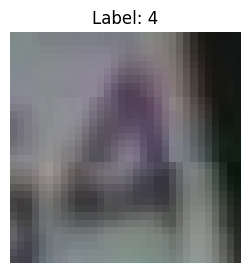

In [ ]:
sample_image, sample_label = next(iter(train_raw))

print("Image shape:", sample_image.shape)
print("Image dtype:", sample_image.dtype)
print("Label:", sample_label.numpy())
print("Minimum pixel value:", tf.reduce_min(sample_image).numpy())
print("Maximum pixel value:", tf.reduce_max(sample_image).numpy())

plt.figure(figsize=(3, 3))
plt.imshow(sample_image)
plt.title(f"Label: {sample_label.numpy()}")
plt.axis("off")
plt.show()

# 7. Display sample images
The samples show variations in lighting, background, image quality, and the appearance of neighboring digits.

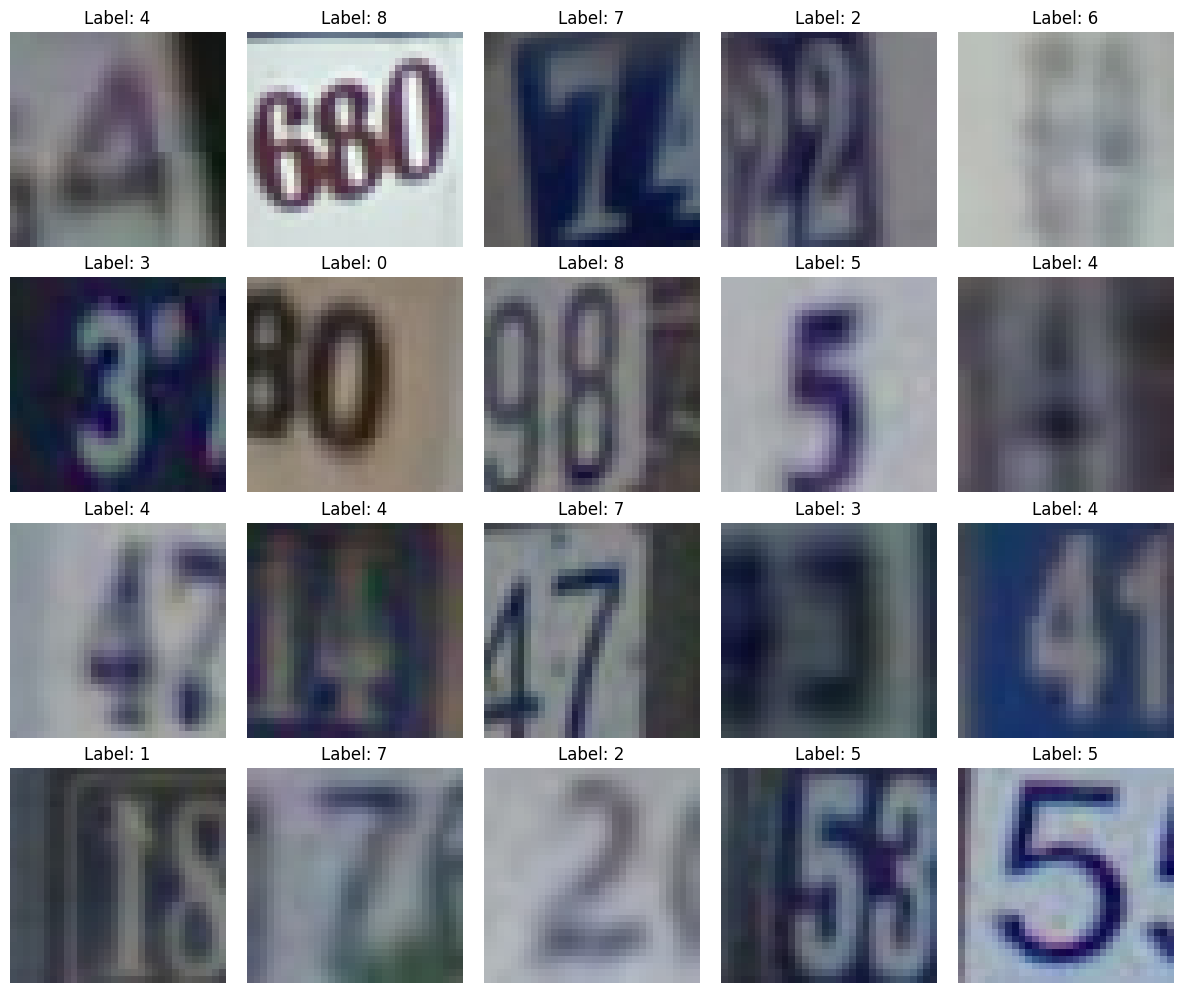

Saved: /content/SVHN_Student_Project/results/sample_images.png


In [ ]:
plt.figure(figsize=(12, 10))

for index, (image, label) in enumerate(train_raw.take(20)):
    plt.subplot(4, 5, index + 1)
    plt.imshow(image)
    plt.title(f"Label: {label.numpy()}")
    plt.axis("off")

plt.tight_layout()
sample_path = RESULTS_DIR / "sample_images.png"
plt.savefig(sample_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", sample_path)

# 8. Analyze class distribution

In [ ]:
class_counts = np.zeros(10, dtype=int)

for _, label in tfds.as_numpy(train_raw):
    class_counts[int(label)] += 1

for digit, count in enumerate(class_counts):
    percentage = count / class_counts.sum() * 100
    print(f"Digit {digit}: {count} images ({percentage:.2f}%)")

Digit 0: 3938 images (6.72%)
Digit 1: 11067 images (18.88%)
Digit 2: 8425 images (14.38%)
Digit 3: 6836 images (11.66%)
Digit 4: 6003 images (10.24%)
Digit 5: 5466 images (9.33%)
Digit 6: 4559 images (7.78%)
Digit 7: 4531 images (7.73%)
Digit 8: 4034 images (6.88%)
Digit 9: 3747 images (6.39%)


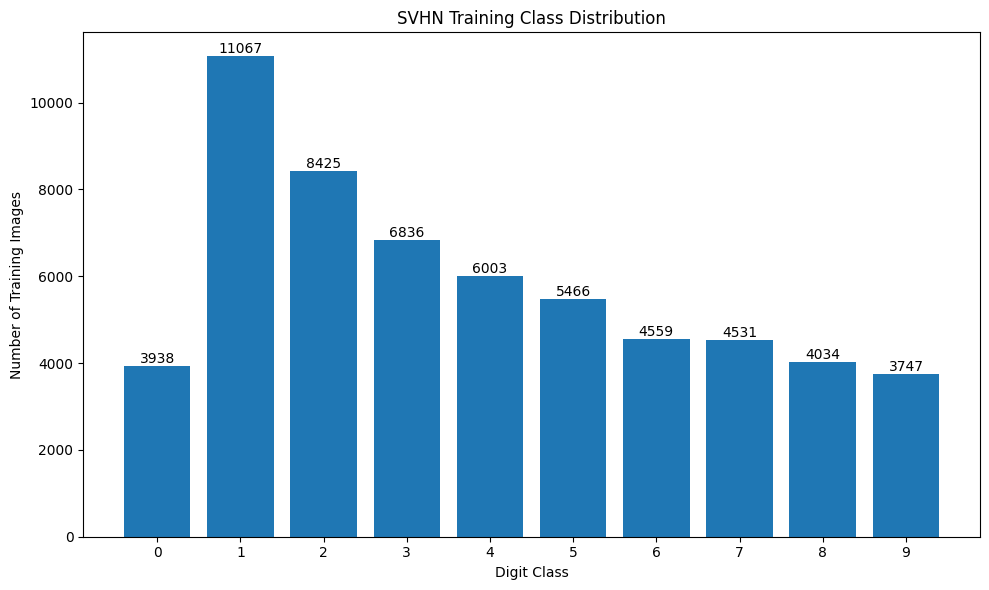

Saved: /content/SVHN_Student_Project/results/class_distribution.png


In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.bar(range(10), class_counts)

plt.xticks(range(10))
plt.xlabel("Digit Class")
plt.ylabel("Number of Training Images")
plt.title("SVHN Training Class Distribution")

for bar, count in zip(bars, class_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
distribution_path = RESULTS_DIR / "class_distribution.png"
plt.savefig(distribution_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", distribution_path)

# 9. Prepare the data
- **Shuffle** changes the order of training samples.
- **Batch** groups 64 images in each training step.
- **Prefetch** prepares the following batch while the current batch is being processed.
- Pixel normalization is performed inside the model.

In [ ]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(dataset, training=False):
    if training:
        dataset = dataset.shuffle(
            10000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_dataset = prepare_dataset(train_raw, training=True)
validation_dataset = prepare_dataset(validation_raw)
test_dataset = prepare_dataset(test_raw)

for images, labels in train_dataset.take(1):
    print("Images batch shape:", images.shape)
    print("Labels batch shape:", labels.shape)

Images batch shape: (64, 32, 32, 3)
Labels batch shape: (64,)


# 10. Build the CNN model

```text
Input 32x32x3
-> Rescaling
-> Conv2D 32 + ReLU
-> MaxPooling
-> Conv2D 64 + ReLU
-> MaxPooling
-> Flatten
-> Dense 128 + ReLU
-> Dropout 0.5
-> Dense 10 + Softmax
```

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3), name="input_image"),
    layers.Rescaling(1.0 / 255, name="normalization"),

    layers.Conv2D(32, (3, 3), activation="relu", name="conv_1"),
    layers.MaxPooling2D((2, 2), name="pool_1"),

    layers.Conv2D(64, (3, 3), activation="relu", name="conv_2"),
    layers.MaxPooling2D((2, 2), name="pool_2"),

    layers.Flatten(name="flatten"),
    layers.Dense(128, activation="relu", name="hidden_dense"),
    layers.Dropout(0.5, name="dropout"),
    layers.Dense(10, activation="softmax", name="output")
], name="SVHN_Simple_CNN")

model.summary()

Model: "SVHN_Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Rescaling)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_dense (Dense)            │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

# 11. Compile the model
Adam is used to update the weights. Sparse Categorical Crossentropy is suitable because the class labels are integers from 0 to 9. Accuracy is used as the main evaluation measure.

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# 12. Train the model
The maximum number of epochs is 20. Early Stopping monitors validation loss and restores the weights from the best epoch.

In [ ]:
EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.5235 - loss: 1.4225 - val_accuracy: 0.8109 - val_loss: 0.6664
Epoch 2/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7745 - loss: 0.7454 - val_accuracy: 0.8400 - val_loss: 0.5446
Epoch 3/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8058 - loss: 0.6428 - val_accuracy: 0.8571 - val_loss: 0.4894
Epoch 4/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8230 - loss: 0.5934 - val_accuracy: 0.8614 - val_loss: 0.4867
Epoch 5/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.8312 - loss: 0.5596 - val_accuracy: 0.8711 - val_loss: 0.4470
Epoch 6/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.8377 - loss: 0.5360 - val_accuracy: 0.8733 - val_loss: 0.4431
Epoch 7/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8457 - loss: 0.5087 - val_accuracy: 0.8789 - val_loss: 0.4276
Epoch 8/20
916/916 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.8489 - loss: 0.4937 - 

# 13. Save the training history

In [ ]:
history_df = pd.DataFrame(history.history)
history_path = RESULTS_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

print(history_df)
print("Saved:", history_path)

    accuracy      loss  val_accuracy  val_loss
0   0.523530  1.422546      0.810934  0.666445
1   0.774545  0.745443      0.840011  0.544612
2   0.805805  0.642850      0.857075  0.489394
3   0.822953  0.593417      0.861375  0.486672
4   0.831229  0.559614      0.871135  0.446974
5   0.837713  0.536048      0.873251  0.443101
6   0.845750  0.508708      0.878916  0.427629
7   0.848940  0.493729      0.879803  0.420212
8   0.855220  0.477306      0.883353  0.407681
9   0.858956  0.460060      0.881851  0.408226
10  0.863598  0.446912      0.885605  0.396719
11  0.867317  0.434639      0.887516  0.393737
12  0.870491  0.423706      0.888540  0.389090
13  0.870866  0.417973      0.880349  0.415952
14  0.873187  0.408526      0.888404  0.391679
15  0.877402  0.396961      0.891065  0.384630
16  0.878835  0.389867      0.892772  0.380946
17  0.879722  0.385144      0.894888  0.377979
18  0.882640  0.374750      0.893727  0.384281
19  0.885694  0.370776      0.893386  0.382977
Saved: /conte

# 14. Plot training and validation accuracy

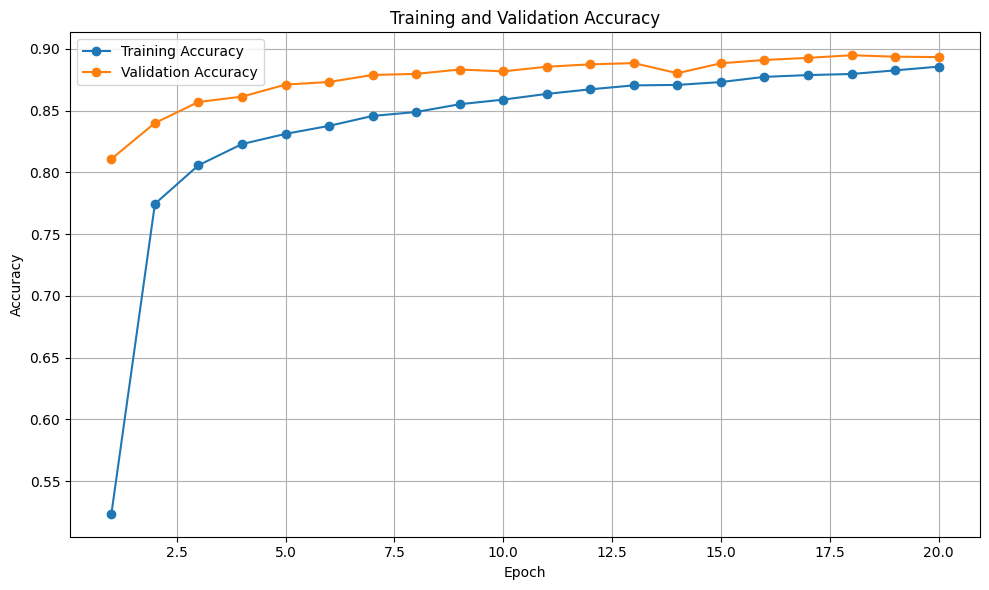

Saved: /content/SVHN_Student_Project/results/accuracy_curve.png


In [ ]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(10, 6))
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_path = RESULTS_DIR / "accuracy_curve.png"
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", accuracy_path)

# 15. Plot training and validation loss

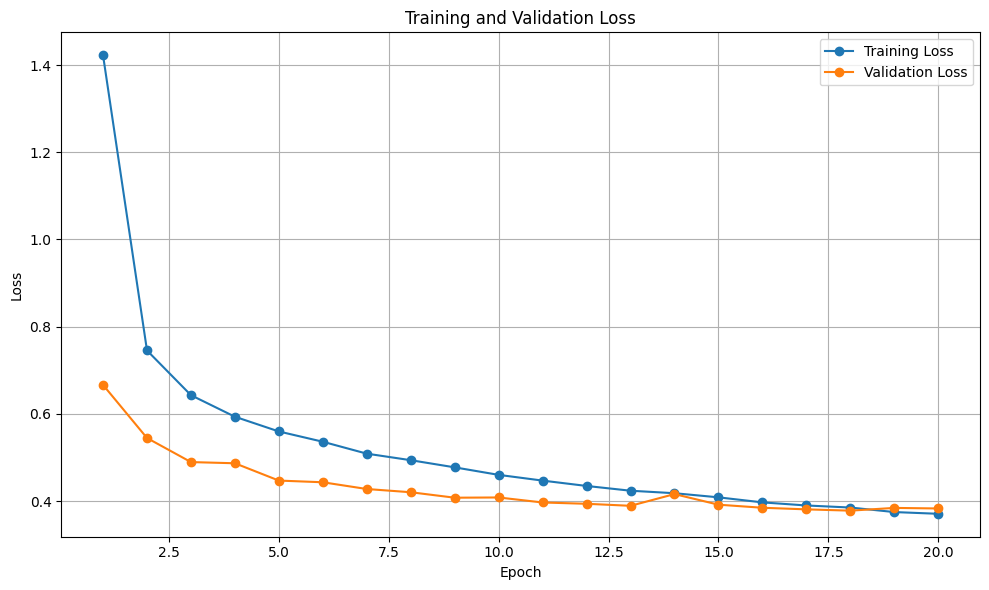

Saved: /content/SVHN_Student_Project/results/loss_curve.png


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_path = RESULTS_DIR / "loss_curve.png"
plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", loss_path)

# 16. Evaluate the model on the test set

In [ ]:
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Test Loss: {test_loss:.6f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8792 - loss: 0.4334
Test Loss: 0.433392
Test Accuracy: 0.8792
Test Accuracy Percentage: 87.92%


# 17. Generate predictions

In [ ]:
y_true = np.concatenate(
    [labels.numpy() for _, labels in test_dataset],
    axis=0
)

y_probabilities = model.predict(test_dataset, verbose=1)
y_predicted = np.argmax(y_probabilities, axis=1)

print("True labels shape:", y_true.shape)
print("Predictions shape:", y_predicted.shape)
print("First 20 true labels:", y_true[:20])
print("First 20 predictions:", y_predicted[:20])

407/407 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step
True labels shape: (26032,)
Predictions shape: (26032,)
First 20 true labels: [2 7 2 4 4 2 6 2 3 1 3 2 1 2 2 1 5 1 3 4]
First 20 predictions: [2 7 2 4 4 2 6 2 3 1 3 2 1 2 5 1 5 1 9 4]


# 18. Classification report
The report gives Precision, Recall, F1-score, and the number of test images for each digit.

In [ ]:
class_names = [str(digit) for digit in range(10)]

report_text = classification_report(
    y_true,
    y_predicted,
    labels=list(range(10)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report_text)

report_path = RESULTS_DIR / "classification_report.txt"
with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_text)

print("Saved:", report_path)

              precision    recall  f1-score   support

           0     0.8963    0.8670    0.8814      1744
           1     0.9320    0.9186    0.9252      5099
           2     0.8936    0.9308    0.9118      4149
           3     0.8535    0.8185    0.8356      2882
           4     0.8721    0.9029    0.8872      2523
           5     0.8343    0.8914    0.8619      2384
           6     0.8643    0.8250    0.8442      1977
           7     0.8837    0.8995    0.8915      2019
           8     0.8742    0.7578    0.8119      1660
           9     0.8045    0.8539    0.8285      1595

    accuracy                         0.8792     26032
   macro avg     0.8708    0.8665    0.8679     26032
weighted avg     0.8796    0.8792    0.8788     26032

Saved: /content/SVHN_Student_Project/results/classification_report.txt


# 19. Confusion matrix
Rows represent the true labels and columns represent the predicted labels. Values on the main diagonal are correct predictions.

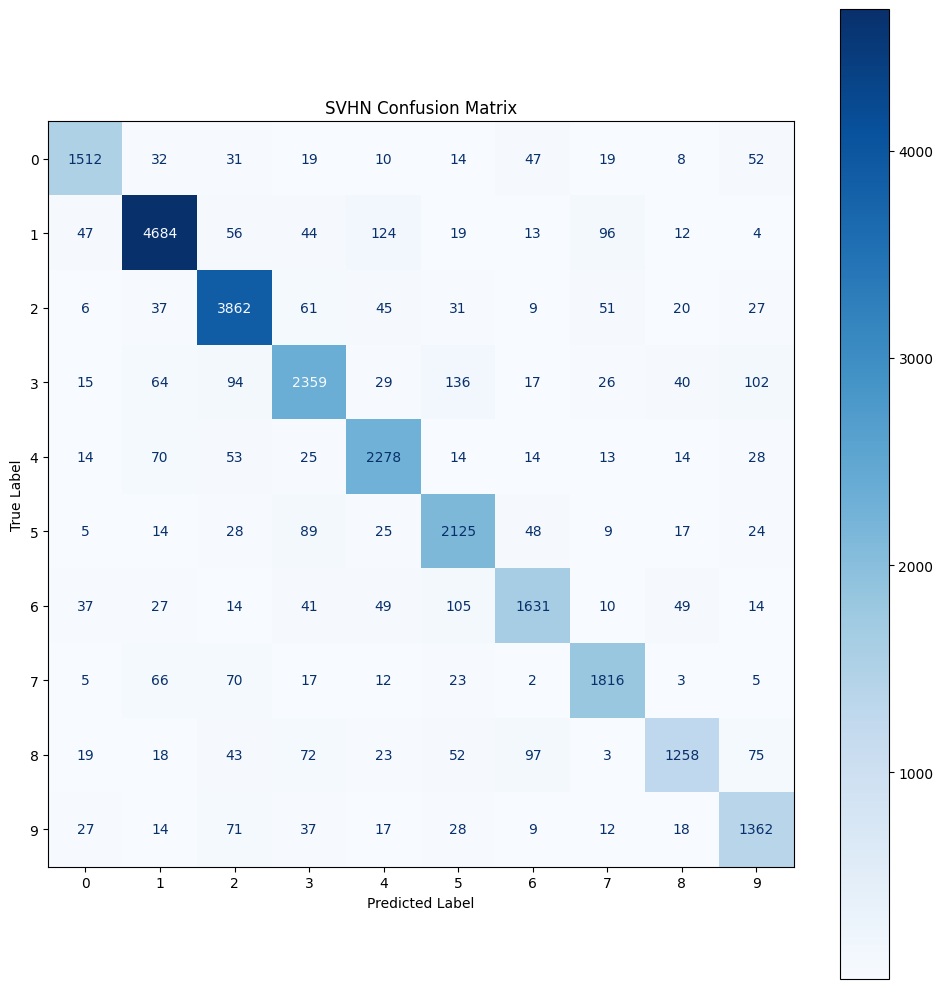

Saved: /content/SVHN_Student_Project/results/confusion_matrix.png


In [ ]:
cm = confusion_matrix(y_true, y_predicted, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(10, 10))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(cmap="Blues", values_format="d", ax=ax)

plt.title("SVHN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

cm_path = RESULTS_DIR / "confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", cm_path)

# 20. Inspect correct and incorrect predictions

In [ ]:
analysis_images = []
analysis_labels = []

for image, label in test_raw.take(500):
    analysis_images.append(image.numpy())
    analysis_labels.append(label.numpy())

analysis_images = np.stack(analysis_images)
analysis_labels = np.array(analysis_labels)

analysis_probabilities = model.predict(analysis_images, verbose=0)
analysis_predictions = np.argmax(analysis_probabilities, axis=1)
analysis_confidences = np.max(analysis_probabilities, axis=1)

def plot_examples(indices, title, save_path):
    count = min(len(indices), 12)
    if count == 0:
        print("No examples available.")
        return

    plt.figure(figsize=(12, 9))

    for plot_index, data_index in enumerate(indices[:count]):
        plt.subplot(3, 4, plot_index + 1)
        plt.imshow(analysis_images[data_index])
        plt.title(
            f"True: {analysis_labels[data_index]}\n"
            f"Predicted: {analysis_predictions[data_index]}\n"
            f"Confidence: {analysis_confidences[data_index] * 100:.1f}%"
        )
        plt.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved:", save_path)

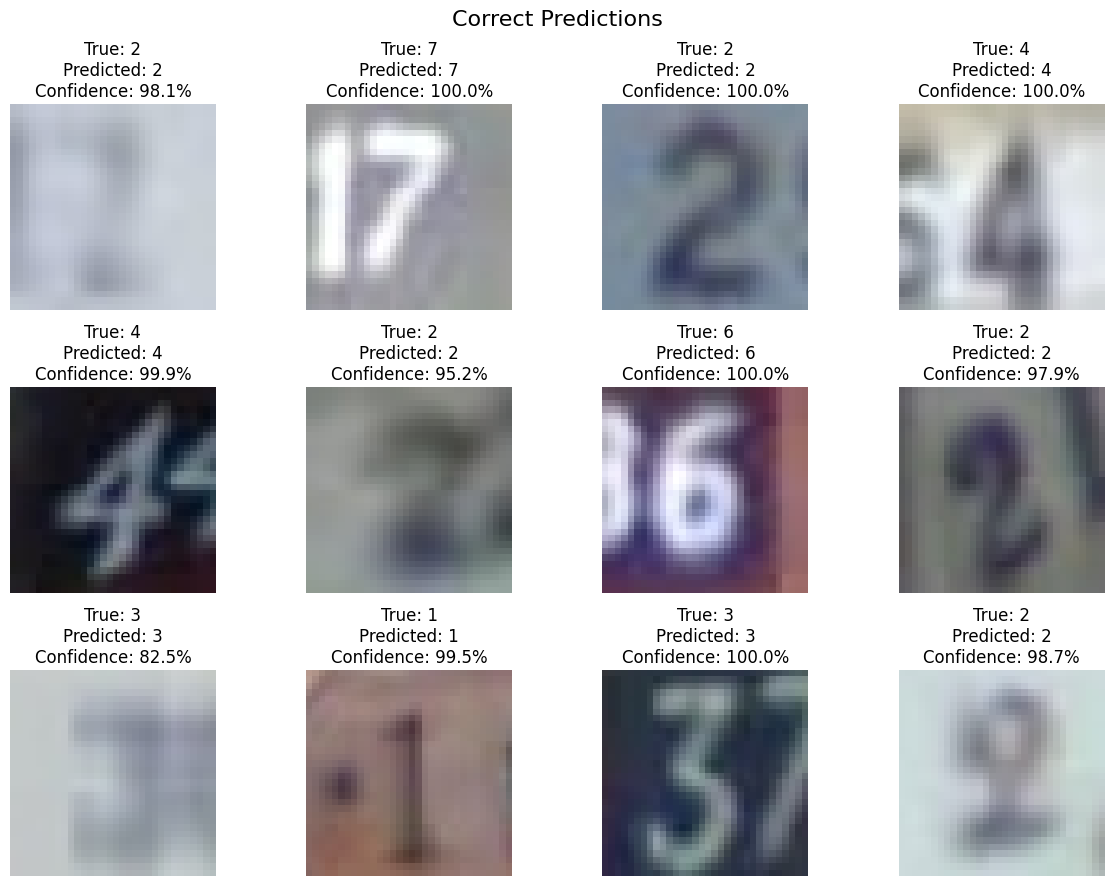

Saved: /content/SVHN_Student_Project/results/correct_predictions.png


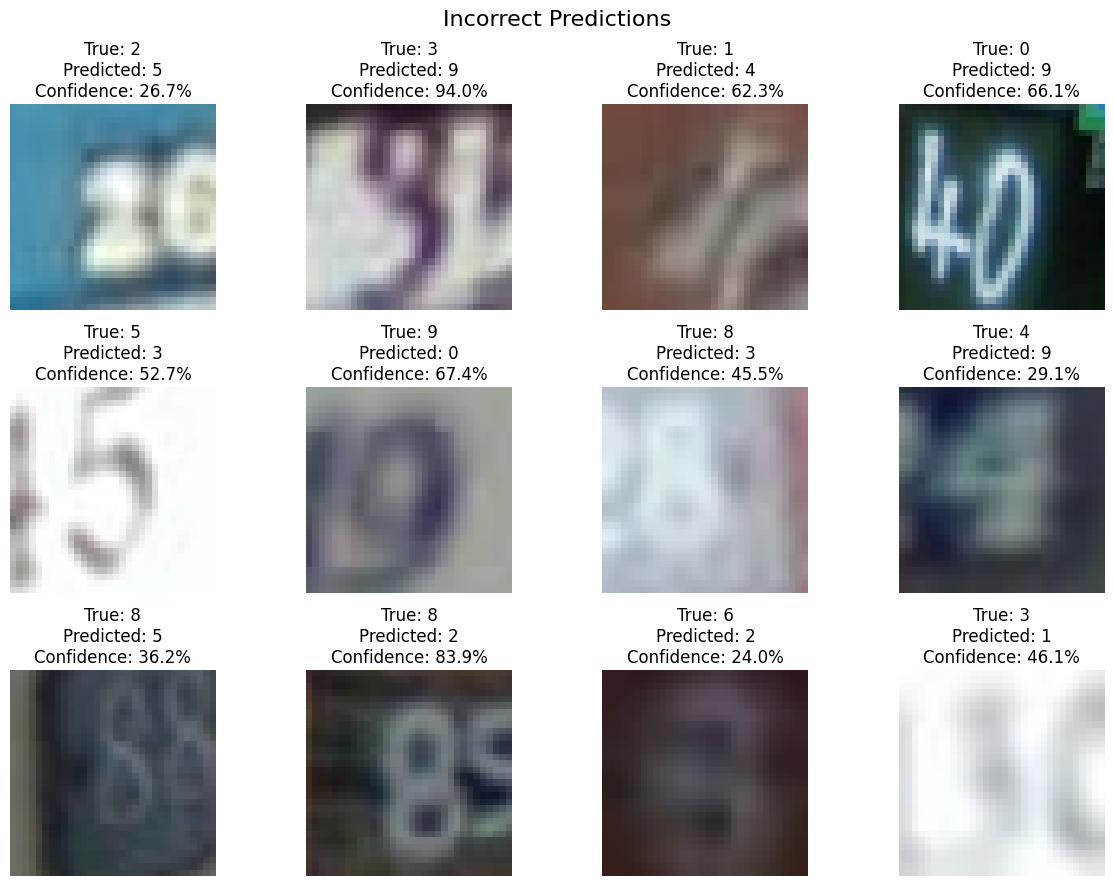

Saved: /content/SVHN_Student_Project/results/incorrect_predictions.png


In [ ]:
correct_indices = np.where(analysis_predictions == analysis_labels)[0]
incorrect_indices = np.where(analysis_predictions != analysis_labels)[0]

plot_examples(
    correct_indices,
    "Correct Predictions",
    RESULTS_DIR / "correct_predictions.png"
)

plot_examples(
    incorrect_indices,
    "Incorrect Predictions",
    RESULTS_DIR / "incorrect_predictions.png"
)

### Possible reasons for incorrect predictions
- Low image quality or weak lighting.
- A small or partially hidden digit.
- Neighboring digits appearing in the crop.
- Similar shapes between some digits.
- A complex or noisy background.

# 21. Save the final model

In [ ]:
model_path = MODEL_DIR / "svhn_simple_cnn.keras"
model.save(model_path)

print("Saved model:", model_path)
print(f"Final test accuracy: {test_accuracy * 100:.2f}%")

Saved model: /content/SVHN_Student_Project/model/svhn_simple_cnn.keras
Final test accuracy: 87.92%


# Final result
The simple CNN achieved **87.92% test accuracy**. The best validation loss was reached at epoch 18. The results show that the model learned useful visual features while remaining small enough for a student project.

## Troubleshooting note
Run the following installation commands only when `TFDS load available` is `False`, then restart the Colab session:

```python
%pip uninstall -y tf-datasets tensorflow-datasets tfds-nightly
%pip install --no-cache-dir --force-reinstall tensorflow-datasets==4.9.10
```